# Your First Neural Network in PyTorch
## Real-World Breast Cancer Classification

**Goal:** Build, train, evaluate, and visualize a neural network in PyTorch using a real-world dataset.

### What we will learn
1. Load a real dataset
2. Understand the data
3. Visualize two features
4. Split data into training and test sets
5. Standardize features
6. Convert data to PyTorch tensors
7. Build a neural network
8. Define loss and optimizer
9. Train the network
10. Plot the learning curve
11. Evaluate on unseen test data
12. Visualize the learned decision boundary
13. Make predictions for new samples



## 1. Import the libraries

We use:
- **NumPy** for numerical operations.
- **Pandas** for looking at the dataset as a table.
- **Matplotlib** for visualization.
- **scikit-learn** to load the real dataset and perform standard preprocessing.
- **PyTorch** to build and train the neural network.

In [ ]:
# NumPy: numerical arrays and calculations
import numpy as np

# Pandas: working with tabular data
import pandas as pd

# Matplotlib: creating graphs and visualizations
import matplotlib.pyplot as plt

# PyTorch: our deep learning framework
import torch
import torch.nn as nn

# scikit-learn utilities
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set random seeds so that the notebook gives reproducible results.
np.random.seed(42)
torch.manual_seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load a real dataset

We will use the **Breast Cancer Wisconsin Diagnostic dataset** available through scikit-learn.

It contains numerical measurements of breast cancer samples and a binary target:
- `0` → malignant
- `1` → benign

In [ ]:
# Load the dataset.
data = load_breast_cancer()

# See what information is available inside the dataset.
print(data.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [ ]:
# Check the number of samples and features.
print("Shape of input data:", data.data.shape)

# Display the two target class names.
print("Target classes:", data.target_names)

# Display all feature names.
print("\nFeature names:")
print(data.feature_names)

Shape of input data: (569, 30)
Target classes: ['malignant' 'benign']

Feature names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


### Understanding the shape

If we see `(569, 30)`, it means:

- **569 samples**
- **30 numerical features for each sample**

One row represents one sample, and the 30 columns describe that sample.

## 3. Put the dataset into a Pandas DataFrame

A DataFrame makes the real dataset easier to inspect.

In [ ]:
# Create a DataFrame containing all 30 features.
df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Add the target column.
df["target"] = data.target

# Display the first five rows.
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
# Check the size of the DataFrame.
print("Rows and columns:", df.shape)

# Check whether there are missing values.
print("\nTotal missing values:", df.isnull().sum().sum())

# See how many examples belong to each class.
print("\nNumber of samples in each class:")
print(df["target"].value_counts().sort_index())

# Make the numeric target mapping explicit.
print("\nTarget mapping:")
for number, name in enumerate(data.target_names):
    print(number, "=", name)

Rows and columns: (569, 31)

Total missing values: 0

Number of samples in each class:
target
0    212
1    357
Name: count, dtype: int64

Target mapping:
0 = malignant
1 = benign


## 4. Choose two features for visualization

The complete dataset has 30 features.

For our **first neural network**, we intentionally use only two:
- `mean radius`
- `mean texture`

Using two features allows us to draw the data in 2D and later visualize the decision boundary learned by the neural network.

This is a teaching choice. A real medical model would require much more careful feature selection, validation, and clinical evaluation.

In [ ]:
# Select two features so that we can visualize the problem.
X = df[["mean radius", "mean texture"]].values

# Target labels:
# 0 = malignant
# 1 = benign
y = df["target"].values

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five input rows:")
print(X[:5])

print("\nFirst five target values:")
print(y[:5])

Input shape: (569, 2)
Target shape: (569,)

First five input rows:
[[17.99 10.38]
 [20.57 17.77]
 [19.69 21.25]
 [11.42 20.38]
 [20.29 14.34]]

First five target values:
[0 0 0 0 0]


## 5. Visualize the real data

Each point is one sample.

- X-axis → mean radius
- Y-axis → mean texture
- The two groups represent the target classes.

Our neural network will try to learn a boundary between these classes.

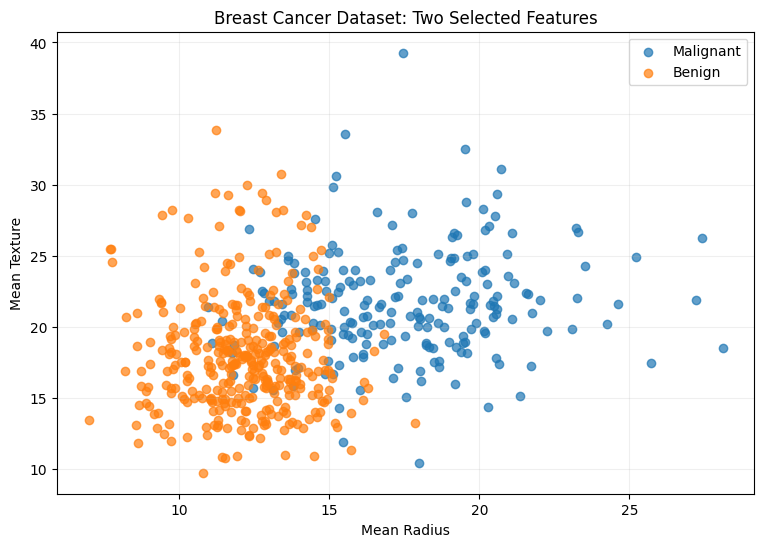

In [ ]:
plt.figure(figsize=(9, 6))

# Plot malignant samples.
plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Malignant",
    alpha=0.7
)

# Plot benign samples.
plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Benign",
    alpha=0.7
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Breast Cancer Dataset: Two Selected Features")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### What should we notice?

The two classes show some visible structure, but they also overlap.

That is exactly the kind of problem we want a machine-learning model to learn.

> **Our neural network will try to learn this structure.**

## 6. Split the data into training and test sets

We should not train and test on exactly the same examples.

We will use:
- **80%** for training
- **20%** for testing

The test set is kept aside so that we can evaluate the model on examples it did not use for learning.

`stratify=y` keeps the class proportions approximately similar in both sets.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

print("\nTraining input shape:", X_train.shape)
print("Test input shape:", X_test.shape)

Training samples: 455
Test samples: 114

Training input shape: (455, 2)
Test input shape: (114, 2)


## 7. Standardize the features

Neural networks usually train more smoothly when numerical features are on comparable scales.

Standardization transforms each feature using its mean and standard deviation.

### Very important
We **fit** the scaler only on the training data.

Then we use the same fitted scaler to transform the test data.

This prevents information from the test set from leaking into the training process.

In [ ]:
# Create the scaler.
scaler = StandardScaler()

# Learn scaling information from TRAINING data
# and transform the training data.
X_train_scaled = scaler.fit_transform(X_train)

# Use the already-fitted scaler on TEST data.
# Notice that we use transform(), not fit_transform().
X_test_scaled = scaler.transform(X_test)

print("First five scaled training samples:")
print(X_train_scaled[:5])

print("\nMean of scaled training features:")
print(X_train_scaled.mean(axis=0))

print("\nStandard deviation of scaled training features:")
print(X_train_scaled.std(axis=0))

First five scaled training samples:
[[-1.07200079 -0.6584246 ]
 [ 1.74874285  0.06650173]
 [-0.97473376 -0.93112416]
 [-0.14510328 -1.2151862 ]
 [-0.77161734 -0.08121053]]

Mean of scaled training features:
[-4.31742554e-15  2.24606658e-15]

Standard deviation of scaled training features:
[1. 1.]


## 8. Convert NumPy arrays into PyTorch tensors

PyTorch neural networks expect data in the form of **tensors**.

We use `float32`, a common numerical format for neural-network computation.

For the labels, we reshape them from `(number_of_samples,)` to `(number_of_samples, 1)` because our network produces one output for each sample.

In [ ]:
# Convert training inputs to PyTorch tensors.
X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

# Convert test inputs to PyTorch tensors.
X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

# Convert training labels to float32 and reshape them.
y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
).reshape(-1, 1)

# Convert test labels in the same way.
y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.float32
).reshape(-1, 1)

print("X_train_tensor shape:", X_train_tensor.shape)
print("y_train_tensor shape:", y_train_tensor.shape)
print("X_test_tensor shape:", X_test_tensor.shape)
print("y_test_tensor shape:", y_test_tensor.shape)

print("\nTensor data type:", X_train_tensor.dtype)

X_train_tensor shape: torch.Size([455, 2])
y_train_tensor shape: torch.Size([455, 1])
X_test_tensor shape: torch.Size([114, 2])
y_test_tensor shape: torch.Size([114, 1])

Tensor data type: torch.float32


# 9. Build our first neural network

Our architecture is:

**2 input features → 8 hidden neurons → 1 output**

The two inputs are:
1. Mean radius
2. Mean texture

We use ReLU after the hidden layer.

In [ ]:
class NeuralNetwork(nn.Module):
    """
    A simple fully connected neural network.

    Architecture:
        2 input features
        -> 8 hidden neurons
        -> 1 output
    """

    def __init__(self):
        # Initialize the parent nn.Module class.
        super().__init__()

        # First layer:
        # 2 input features -> 8 hidden neurons
        self.hidden = nn.Linear(2, 8)

        # Output layer:
        # 8 hidden values -> 1 output
        self.output = nn.Linear(8, 1)

    def forward(self, x):
        # Pass the input through the hidden linear layer.
        x = self.hidden(x)

        # Apply the ReLU activation function.
        x = torch.relu(x)

        # Pass the activated values to the output layer.
        x = self.output(x)

        # Return the raw output, called a logit.
        return x


# Create the neural network.
model = NeuralNetwork()

# Display the architecture.
print(model)

NeuralNetwork(
  (hidden): Linear(in_features=2, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
)


## 10. Understand `nn.Linear`

When we write:

```python
nn.Linear(2, 8)
```

we mean:

**2 input values → 8 output values**

Each neuron performs a weighted sum plus a bias:

`z = w1*x1 + w2*x2 + b`

The weights and biases are the **parameters** that the network learns during training.

The second layer:

```python
nn.Linear(8, 1)
```

takes the 8 hidden values and produces one final output.

In [ ]:
# Count all trainable parameters in the network.
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print("Total trainable parameters:", total_parameters)

# Show the shape of every trainable parameter.
for name, parameter in model.named_parameters():
    print(f"{name}: {tuple(parameter.shape)}")

Total trainable parameters: 33
hidden.weight: (8, 2)
hidden.bias: (8,)
output.weight: (1, 8)
output.bias: (1,)


## 11. Try one forward pass before training

Our network starts with randomly initialized weights.

So before training, its predictions will generally not be good.

A **forward pass** means sending input data through the network to obtain an output.

In [ ]:
# We are only testing the network here, not training it.
# Therefore gradients are not required.
with torch.no_grad():
    initial_outputs = model(X_train_tensor[:5])

print("Initial raw outputs:")
print(initial_outputs)

Initial raw outputs:
tensor([[ 0.1635],
        [-0.5949],
        [ 0.1765],
        [ 0.1176],
        [ 0.0694]])


The values above are **raw outputs (logits)**, not probabilities.

For binary classification, we can apply the sigmoid function later to convert a logit into a number between 0 and 1.

## 12. Define the loss function

We have a binary classification problem.

We use `BCEWithLogitsLoss`.

It combines the sigmoid operation and binary cross-entropy loss internally in a numerically stable way.

Therefore, we do **not** add a sigmoid layer to the model itself.

In [ ]:
# Loss function for binary classification.
loss_function = nn.BCEWithLogitsLoss()

print(loss_function)

BCEWithLogitsLoss()


## 13. Define the optimizer

The optimizer updates the model's weights and biases using the gradients calculated during backpropagation.

We use Adam for this first practical example.

`lr` means learning rate — it controls the size of parameter updates.

In [ ]:
# Adam optimizer.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


# 14. Train the neural network

For every epoch, we perform:

1. **Forward pass** → make predictions
2. **Calculate loss** → measure the error
3. **Clear old gradients**
4. **Backpropagation** → calculate new gradients
5. **Optimizer step** → update weights

We repeat these steps many times.

In [ ]:
# Number of complete passes through the training data.
epochs = 500

# Store the loss after every epoch so that we can plot it later.
loss_history = []

for epoch in range(epochs):

    # ---------------------------------------------------------
    # STEP 1: FORWARD PASS
    # Send the training data through the neural network.
    # ---------------------------------------------------------
    predictions = model(X_train_tensor)

    # ---------------------------------------------------------
    # STEP 2: CALCULATE LOSS
    # Compare predictions with the correct labels.
    # ---------------------------------------------------------
    loss = loss_function(
        predictions,
        y_train_tensor
    )

    # ---------------------------------------------------------
    # STEP 3: CLEAR OLD GRADIENTS
    # PyTorch accumulates gradients by default.
    # ---------------------------------------------------------
    optimizer.zero_grad()

    # ---------------------------------------------------------
    # STEP 4: BACKPROPAGATION
    # Calculate gradients of the loss with respect to
    # the trainable parameters.
    # ---------------------------------------------------------
    loss.backward()

    # ---------------------------------------------------------
    # STEP 5: UPDATE PARAMETERS
    # Use the gradients to update weights and biases.
    # ---------------------------------------------------------
    optimizer.step()

    # Store the numerical loss value for visualization.
    loss_history.append(loss.item())

    # Print progress every 50 epochs.
    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d}/{epochs} | "
            f"Loss: {loss.item():.4f}"
        )

Epoch  50/500 | Loss: 0.3863
Epoch 100/500 | Loss: 0.2807
Epoch 150/500 | Loss: 0.2460
Epoch 200/500 | Loss: 0.2343
Epoch 250/500 | Loss: 0.2275
Epoch 300/500 | Loss: 0.2260
Epoch 350/500 | Loss: 0.2256
Epoch 400/500 | Loss: 0.2254
Epoch 450/500 | Loss: 0.2253
Epoch 500/500 | Loss: 0.2253


## 15. Visualize the training loss

The loss tells us how far the model's predictions are from the correct answers.

If training is working, we generally expect the loss to decrease.

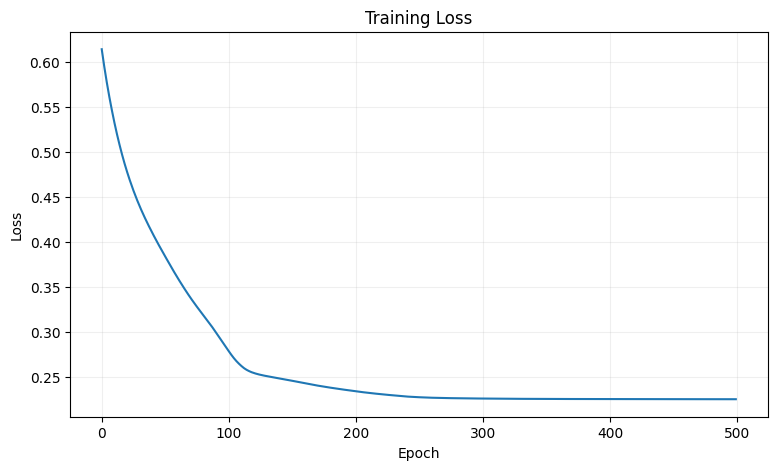

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(alpha=0.2)

plt.show()

### What does this graph mean?

At the beginning, the network has randomly initialized parameters.

As training continues:
- predictions improve,
- loss generally decreases,
- the model learns better parameter values.

> **The loss curve is a visual story of the network learning.**

## 16. Evaluate the model on unseen test data

Now we use the 20% of the data that was kept aside.

This data was **not used to update the model's parameters**.

We switch the model to evaluation mode and turn off gradient calculation because we are only making predictions.

In [ ]:
# Put the model into evaluation mode.
model.eval()

# We do not need gradients while evaluating.
with torch.no_grad():

    # Get raw outputs (logits).
    test_logits = model(X_test_tensor)

    # Convert logits to probabilities between 0 and 1.
    test_probabilities = torch.sigmoid(test_logits)

    # Use 0.5 as the classification threshold.
    test_predictions = (
        test_probabilities >= 0.5
    ).float()

# Calculate test accuracy.
test_accuracy = (
    test_predictions == y_test_tensor
).float().mean()

print(
    f"Test Accuracy: {test_accuracy.item() * 100:.2f}%"
)

Test Accuracy: 88.60%


## 17. Inspect individual predictions

Accuracy gives us one summary number.

Let's also look at individual test predictions.

Remember:
- Probability close to 0 → model leans toward class 0
- Probability close to 1 → model leans toward class 1

In [ ]:
# Display the first 15 test examples.
for i in range(min(15, len(y_test))):

    actual = int(y_test[i])
    probability = test_probabilities[i].item()
    predicted = int(test_predictions[i].item())

    print(
        f"Sample {i + 1:2d} | "
        f"Actual: {actual} | "
        f"Probability: {probability:.3f} | "
        f"Predicted: {predicted}"
    )

Sample  1 | Actual: 0 | Probability: 0.000 | Predicted: 0
Sample  2 | Actual: 1 | Probability: 0.977 | Predicted: 1
Sample  3 | Actual: 0 | Probability: 0.491 | Predicted: 0
Sample  4 | Actual: 1 | Probability: 0.078 | Predicted: 0
Sample  5 | Actual: 0 | Probability: 0.000 | Predicted: 0
Sample  6 | Actual: 1 | Probability: 0.883 | Predicted: 1
Sample  7 | Actual: 1 | Probability: 0.989 | Predicted: 1
Sample  8 | Actual: 0 | Probability: 0.000 | Predicted: 0
Sample  9 | Actual: 0 | Probability: 0.001 | Predicted: 0
Sample 10 | Actual: 0 | Probability: 0.000 | Predicted: 0
Sample 11 | Actual: 1 | Probability: 0.962 | Predicted: 1
Sample 12 | Actual: 0 | Probability: 0.380 | Predicted: 0
Sample 13 | Actual: 1 | Probability: 0.975 | Predicted: 1
Sample 14 | Actual: 0 | Probability: 0.006 | Predicted: 0
Sample 15 | Actual: 0 | Probability: 0.132 | Predicted: 0


## 18. Visualize the learned decision boundary

Because we used only two input features, we can visualize what the trained neural network predicts across the feature space.

We will:
1. Create many points covering the feature space.
2. Scale them using the scaler fitted on the training data.
3. Ask the network to classify every point.
4. Plot the resulting prediction regions.
5. Place the real test samples on top.

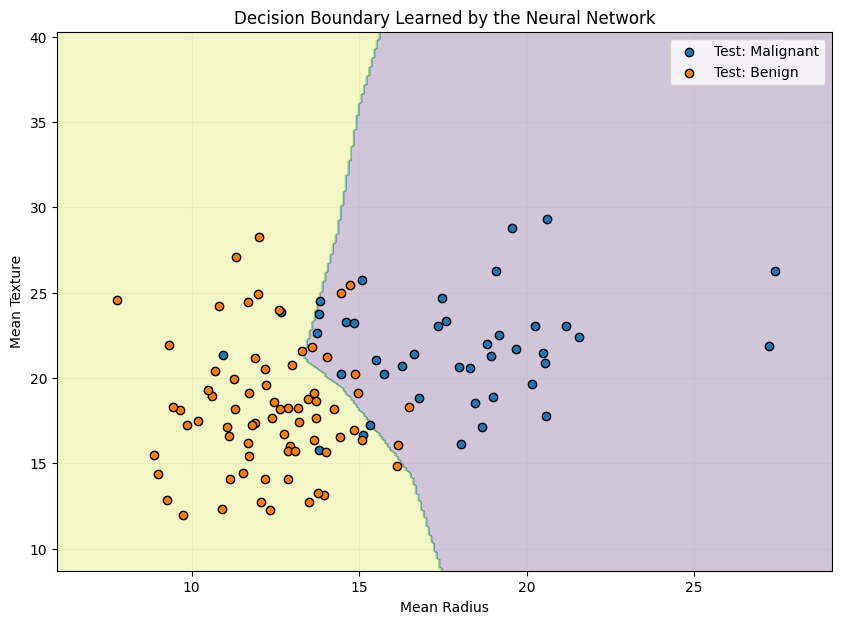

In [ ]:
# Return the model to evaluation mode.
model.eval()

# Find the original feature ranges.
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

# Create a dense 2D grid.
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Convert every grid coordinate into one sample:
# [mean radius, mean texture]
grid_points = np.c_[
    xx.ravel(),
    yy.ravel()
]

# The model was trained on standardized features,
# so the grid must be standardized using the SAME scaler.
grid_points_scaled = scaler.transform(grid_points)

# Convert the grid into a PyTorch tensor.
grid_tensor = torch.tensor(
    grid_points_scaled,
    dtype=torch.float32
)

# Predict the class for every point in the grid.
with torch.no_grad():
    grid_logits = model(grid_tensor)
    grid_probabilities = torch.sigmoid(grid_logits)

# Convert probabilities into class labels.
grid_predictions = (
    grid_probabilities >= 0.5
).float()

# Reshape predictions to the 2D grid.
grid_predictions = grid_predictions.numpy().reshape(xx.shape)

# Plot the learned prediction regions.
plt.figure(figsize=(10, 7))

plt.contourf(
    xx,
    yy,
    grid_predictions,
    alpha=0.25
)

# Plot the test samples on top.
plt.scatter(
    X_test[y_test == 0, 0],
    X_test[y_test == 0, 1],
    label="Test: Malignant",
    edgecolor="black"
)

plt.scatter(
    X_test[y_test == 1, 0],
    X_test[y_test == 1, 1],
    label="Test: Benign",
    edgecolor="black"
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Decision Boundary Learned by the Neural Network")
plt.legend()
plt.grid(alpha=0.15)

plt.show()

### What are we looking at?

The dots are the actual test samples.

The background represents what the neural network predicts in different parts of the feature space.

The boundary between the regions is the model's **learned decision boundary**.

This gives us a visual answer to:

> **“What has the neural network actually learned?”**

## 19. Make predictions for new samples

Now let's perform inference on a few hypothetical feature values.

**Important:** These are demonstration inputs, not clinical predictions.

In [ ]:
# Three hypothetical new samples.
# Columns:
# [mean radius, mean texture]
new_samples = np.array([
    [12.0, 15.0],
    [18.0, 20.0],
    [14.0, 17.0]
])

# Apply exactly the same scaling learned from the training data.
new_samples_scaled = scaler.transform(new_samples)

# Convert to a PyTorch tensor.
new_tensor = torch.tensor(
    new_samples_scaled,
    dtype=torch.float32
)

# Make predictions.
model.eval()

with torch.no_grad():

    new_logits = model(new_tensor)

    new_probabilities = torch.sigmoid(
        new_logits
    )

    new_predictions = (
        new_probabilities >= 0.5
    ).float()

# Display the results.
for i in range(len(new_samples)):

    probability = new_probabilities[i].item()
    predicted_class = int(new_predictions[i].item())

    class_name = (
        "Malignant" if predicted_class == 0
        else "Benign"
    )

    print(
        f"Sample {i + 1}: "
        f"Features = {new_samples[i]} | "
        f"Probability = {probability:.3f} | "
        f"Predicted class = {predicted_class} ({class_name})"
    )

Sample 1: Features = [12. 15.] | Probability = 0.973 | Predicted class = 1 (Benign)
Sample 2: Features = [18. 20.] | Probability = 0.003 | Predicted class = 0 (Malignant)
Sample 3: Features = [14. 17.] | Probability = 0.878 | Predicted class = 1 (Benign)


# 20. The complete PyTorch training workflow

We have implemented the complete basic workflow:

```text
Real-world data
      ↓
Train / test split
      ↓
Feature scaling
      ↓
PyTorch tensors
      ↓
Neural network
      ↓
Forward pass
      ↓
Loss
      ↓
Backpropagation
      ↓
Optimizer update
      ↓
Repeat
      ↓
Trained model
      ↓
Unseen test data
      ↓
Prediction
```

### The five lines to remember

```python
predictions = model(X_train_tensor)

loss = loss_function(predictions, y_train_tensor)

optimizer.zero_grad()

loss.backward()

optimizer.step()
```

These five steps form the core of the training loop we will keep seeing throughout deep learning.

# 21. Parameters vs hyperparameters

### Parameters — learned by the network
- Weights
- Biases

### Hyperparameters — chosen by us
- Number of hidden neurons: `8`
- Learning rate: `0.01`
- Number of epochs: `500`
- Train/test ratio: `80/20`

The network learns its parameters during training, while we choose the hyperparameters.

# 22. Final takeaway

You have now built your first neural network in PyTorch.

You started with **real data**, visualized it, prepared it, converted it into tensors, built a neural network, trained it using backpropagation and an optimizer, evaluated it on unseen data, and visualized the decision boundary.

> **PyTorch lets us turn the mathematical ideas of neural networks into an executable training pipeline.**

### Next step

A natural follow-up is to move from this deliberately simple two-feature example to:
- all 30 features,
- mini-batches,
- `Dataset`,
- `DataLoader`,
- validation data,
- training vs validation loss,
- and overfitting.